# CT Contrast Detection Using Deep Learning
**Dataset:** Kaggle `kmader/siim-medical-images` | **Framework:** PyTorch | **Runtime:** Colab (GPU optional, T4 recommended)

**Pipeline:** 1) Setup and data loading, 2) EDA, 3) Preprocessing and patient-level splits, 4) Baselines and deep models with cross-validation, 5) Results, ROC and confusion matrices, 6) Grad-CAM, 7) Limitations.

Run the cells top to bottom. Each section prints checks, so read the outputs before trusting later cells. Several assumptions about the dataset (column names, patient IDs) are verified in code and not taken for granted.

## 1. Setup and data loading

In [1]:
!pip -q install pydicom kagglehub

In [2]:
import os, random, hashlib, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import pydicom
from scipy import ndimage, stats
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay)
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models
from torchvision.transforms import v2

warnings.filterwarnings('ignore')
SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)
FIG_DIR = Path('/content/results'); FIG_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid')

Device: cpu


**Download.** `kagglehub` works for public datasets in Colab. If it asks for credentials, upload your `kaggle.json` (Kaggle > Settings > API > Create New Token) and run the fallback cell below instead.

In [3]:
import kagglehub
DATA_DIR = Path(kagglehub.dataset_download('kmader/siim-medical-images'))
print(DATA_DIR)

100%|██████████| 250M/250M [00:02<00:00, 89.7MB/s]

Extracting files...


/root/.cache/kagglehub/datasets/kmader/siim-medical-images/versions/6


In [4]:
# FALLBACK (only if the cell above fails): upload kaggle.json first
# from google.colab import files; files.upload()
# !mkdir -p ~/.kaggle && cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
# !kaggle datasets download -d kmader/siim-medical-images -p /content/siim --unzip
# DATA_DIR = Path('/content/siim')

In [5]:
for p in sorted(DATA_DIR.rglob('*'))[:15]: print(p.relative_to(DATA_DIR))
print('... total files:', sum(1 for _ in DATA_DIR.rglob('*') if _.is_file()))
csv_path = next(DATA_DIR.rglob('overview.csv'))
df = pd.read_csv(csv_path)
print(df.shape); print(df.dtypes); df.head()

dicom_dir
dicom_dir/ID_0000_AGE_0060_CONTRAST_1_CT.dcm
dicom_dir/ID_0001_AGE_0069_CONTRAST_1_CT.dcm
dicom_dir/ID_0002_AGE_0074_CONTRAST_1_CT.dcm
dicom_dir/ID_0003_AGE_0075_CONTRAST_1_CT.dcm
dicom_dir/ID_0004_AGE_0056_CONTRAST_1_CT.dcm
dicom_dir/ID_0005_AGE_0048_CONTRAST_1_CT.dcm
dicom_dir/ID_0006_AGE_0075_CONTRAST_1_CT.dcm
dicom_dir/ID_0007_AGE_0061_CONTRAST_1_CT.dcm
dicom_dir/ID_0008_AGE_0051_CONTRAST_1_CT.dcm
dicom_dir/ID_0009_AGE_0048_CONTRAST_1_CT.dcm
dicom_dir/ID_0010_AGE_0060_CONTRAST_1_CT.dcm
dicom_dir/ID_0011_AGE_0061_CONTRAST_1_CT.dcm
dicom_dir/ID_0012_AGE_0061_CONTRAST_1_CT.dcm
dicom_dir/ID_0013_AGE_0060_CONTRAST_1_CT.dcm
... total files: 202
(100, 8)
Unnamed: 0         int64
Age                int64
Contrast            bool
ContrastTag       object
raw_input_path    object
id                 int64
tiff_name         object
dicom_name        object
dtype: object


,Unnamed: 0,Age,Contrast,ContrastTag,raw_input_path,id,tiff_name,dicom_name
0,0,60,True,NONE,../data/50_50_dicom_cases\Contrast\00001 (1).dcm,0,ID_0000_AGE_0060_CONTRAST_1_CT.tif,ID_0000_AGE_0060_CONTRAST_1_CT.dcm
1,1,69,True,NONE,../data/50_50_dicom_cases\Contrast\00001 (10).dcm,1,ID_0001_AGE_0069_CONTRAST_1_CT.tif,ID_0001_AGE_0069_CONTRAST_1_CT.dcm
2,2,74,True,APPLIED,../data/50_50_dicom_cases\Contrast\00001 (11).dcm,2,ID_0002_AGE_0074_CONTRAST_1_CT.tif,ID_0002_AGE_0074_CONTRAST_1_CT.dcm
3,3,75,True,NONE,../data/50_50_dicom_cases\Contrast\00001 (12).dcm,3,ID_0003_AGE_0075_CONTRAST_1_CT.tif,ID_0003_AGE_0075_CONTRAST_1_CT.dcm
4,4,56,True,NONE,../data/50_50_dicom_cases\Contrast\00001 (13).dcm,4,ID_0004_AGE_0056_CONTRAST_1_CT.tif,ID_0004_AGE_0056_CONTRAST_1_CT.dcm


In [6]:
# Locate the label and DICOM file columns instead of assuming them
label_col = next(c for c in df.columns if c.lower() == 'contrast')
name_col = next((c for c in df.columns if 'dicom' in c.lower() and 'name' in c.lower()), None)
dcm_files = {p.name: p for p in DATA_DIR.rglob('*.dcm')}
print('label column:', label_col, '| dicom name column:', name_col, '| .dcm files found:', len(dcm_files))
assert name_col is not None and len(dcm_files) > 0, 'Could not match overview.csv rows to DICOM files; inspect df.columns and the folder listing.'
df['dcm_path'] = df[name_col].map(dcm_files)
assert df['dcm_path'].notna().all(), f"{df['dcm_path'].isna().sum()} rows have no matching DICOM file"
df['y'] = df[label_col].astype(str).str.lower().isin(['true', '1']).astype(int)
print(df['y'].value_counts())

label column: Contrast | dicom name column: dicom_name | .dcm files found: 100
y
1    50
0    50
Name: count, dtype: int64


In [7]:
def read_dicom(path):
    ds = pydicom.dcmread(str(path))
    arr = ds.pixel_array.astype(np.float32)
    hu = arr * float(getattr(ds, 'RescaleSlope', 1)) + float(getattr(ds, 'RescaleIntercept', 0))
    meta = {k: str(getattr(ds, k, '')) for k in
            ['PatientID', 'PatientAge', 'PatientSex', 'Manufacturer', 'SliceThickness', 'KVP',
             'ContrastBolusAgent', 'BodyPartExamined', 'PixelSpacing', 'Rows', 'Columns']}
    return hu, meta

hus, metas = [], []
for p in df['dcm_path']:
    hu, m = read_dicom(p); hus.append(hu); metas.append(m)
meta_df = pd.DataFrame(metas)
df = pd.concat([df.reset_index(drop=True), meta_df.add_prefix('dcm_')], axis=1)
print('image shapes:', {h.shape for h in hus})
print('HU range overall: %.0f to %.0f' % (min(h.min() for h in hus), max(h.max() for h in hus)))
df.filter(like='dcm_').nunique()

hashes = [hashlib.md5(h.tobytes()).hexdigest() for h in hus]
keep = [i for i, hh in enumerate(hashes) if hashes.index(hh) == i]
df = df.iloc[keep].reset_index(drop=True)
hus = [hus[i] for i in keep]
print('Images after removing duplicates:', len(df))

image shapes: {(512, 512)}
HU range overall: -3024 to 3072
Images after removing duplicates: 94


## 2. Exploratory data analysis

### 2.1 Class balance, metadata and the patient-level structure

Class counts (0 = no contrast, 1 = contrast):
y
0    47
1    47
Name: count, dtype: int64

Unique values per DICOM metadata field:
dcm_path                  94
dcm_PatientID             54
dcm_PatientAge            32
dcm_PatientSex             2
dcm_Manufacturer           2
dcm_SliceThickness        12
dcm_KVP                    7
dcm_ContrastBolusAgent     8
dcm_BodyPartExamined       2
dcm_PixelSpacing          55
dcm_Rows                   1
dcm_Columns                1
dtype: int64

Unique PatientIDs: 54 for 94 images


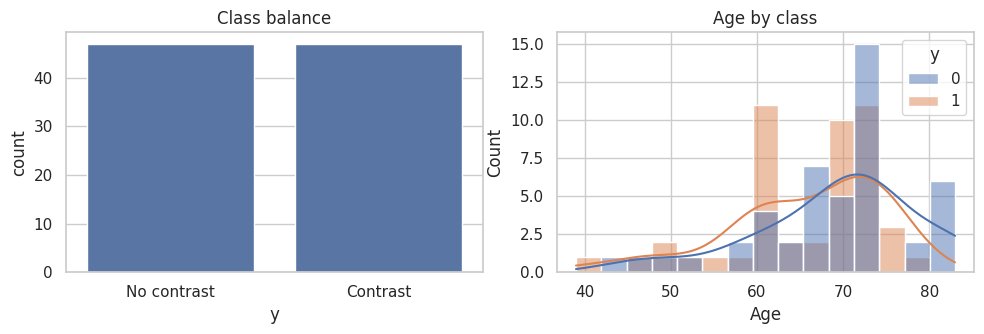

Age (no contrast) mean 69.2 | (contrast) mean 65.7 | Mann-Whitney p = 0.104


In [8]:
print('Class counts (0 = no contrast, 1 = contrast):'); print(df['y'].value_counts().sort_index())
print('\nUnique values per DICOM metadata field:'); print(df.filter(like='dcm_').nunique())
n_pat = df['dcm_PatientID'].nunique()
print(f'\nUnique PatientIDs: {n_pat} for {len(df)} images')
if n_pat == len(df):
    print('WARNING: every image has a different PatientID, so patient-level grouping cannot detect shared patients. '
          'Check other fields (age, scanner, acquisition) before assuming the images are independent.')
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
sns.countplot(x='y', data=df, ax=ax[0]); ax[0].set_title('Class balance'); ax[0].set_xticklabels(['No contrast', 'Contrast'])
age_col = next((c for c in df.columns if c.lower() == 'age'), None)
if age_col:
    sns.histplot(data=df, x=age_col, hue='y', kde=True, bins=15, ax=ax[1]); ax[1].set_title('Age by class')
plt.tight_layout(); plt.savefig(FIG_DIR / 'eda_balance_age.png', dpi=150); plt.show()
if age_col:
    a0, a1 = df.loc[df.y == 0, age_col], df.loc[df.y == 1, age_col]
    print('Age (no contrast) mean %.1f | (contrast) mean %.1f | Mann-Whitney p = %.3f' % (a0.mean(), a1.mean(), stats.mannwhitneyu(a0, a1).pvalue))

In [9]:
# Does any DICOM contrast tag agree with the label?
if df['dcm_ContrastBolusAgent'].nunique() > 1:
    print(pd.crosstab(df['dcm_ContrastBolusAgent'], df['y']))
else:
    print('ContrastBolusAgent tag is uninformative here:', df['dcm_ContrastBolusAgent'].unique())
    print('This is the metadata problem the literature describes, and the reason to classify from pixels.')

y                          0   1
dcm_ContrastBolusAgent          
                          47  36
&                          0   1
100 ML OPTI 350            0   2
125CC OPTIRAY              0   1
APPLIED                    0   4
ISOVUE                     0   1
O                          0   1
REDI CAT & 125CC OPTIRAY   0   1


### 2.2 Sample images (soft-tissue window)

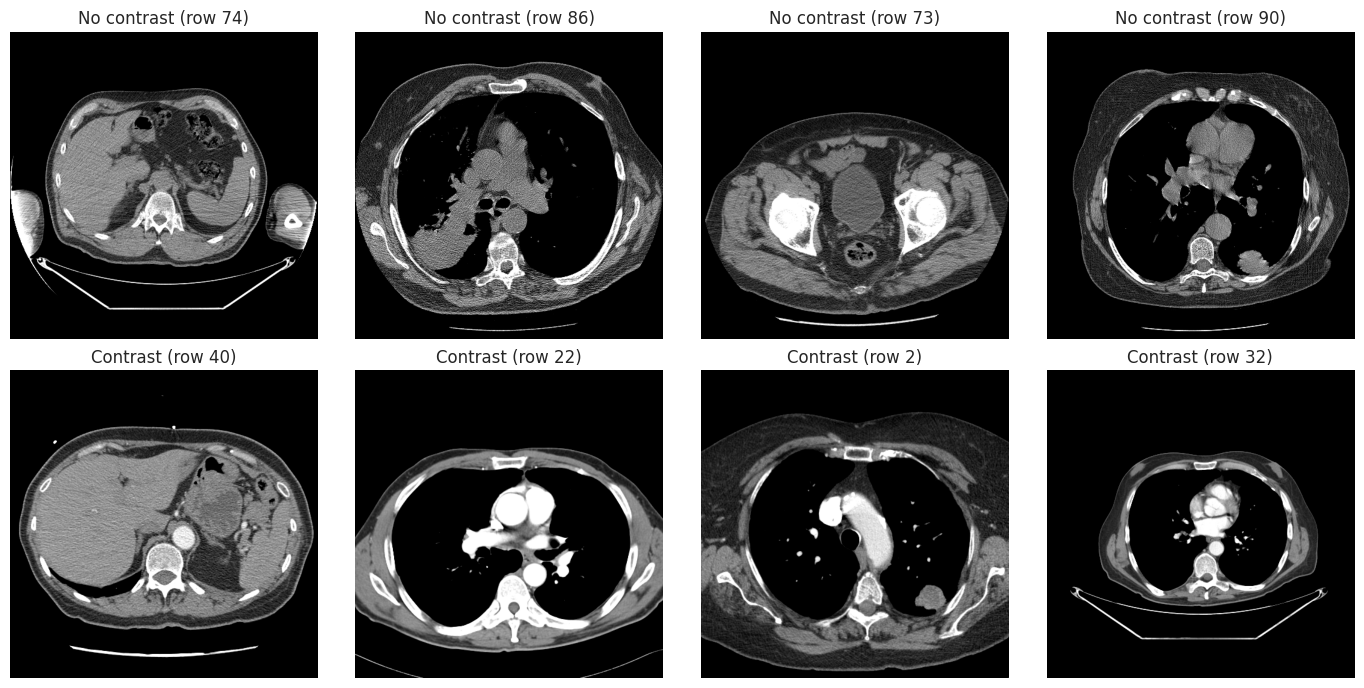

In [10]:
LO, HI = -160, 240   # soft-tissue window (level 40, width 400); configurable
def window(hu, lo=LO, hi=HI): return np.clip((hu - lo) / (hi - lo), 0, 1)
rng = np.random.RandomState(SEED)
idx0 = rng.choice(np.where(df.y == 0)[0], 4, replace=False); idx1 = rng.choice(np.where(df.y == 1)[0], 4, replace=False)
fig, axs = plt.subplots(2, 4, figsize=(14, 7))
for r, idxs in enumerate([idx0, idx1]):
    for c, i in enumerate(idxs):
        axs[r, c].imshow(window(hus[i]), cmap='gray'); axs[r, c].axis('off')
        axs[r, c].set_title(('Contrast' if r else 'No contrast') + f' (row {i})')
plt.tight_layout(); plt.savefig(FIG_DIR / 'eda_samples.png', dpi=150); plt.show()

### 2.3 Intensity (HU) analysis by class

   body_frac  st_mean     st_std        p50         p90         p99
y                                                                  
0       0.46    16.41  71.879997 -47.759998   84.459999  477.700012
1       0.53    37.27  88.519997 -63.919998  161.610001  515.570007
st_mean: Mann-Whitney p = 2.965e-06
p90: Mann-Whitney p = 4.159e-11
p99: Mann-Whitney p = 0.3543


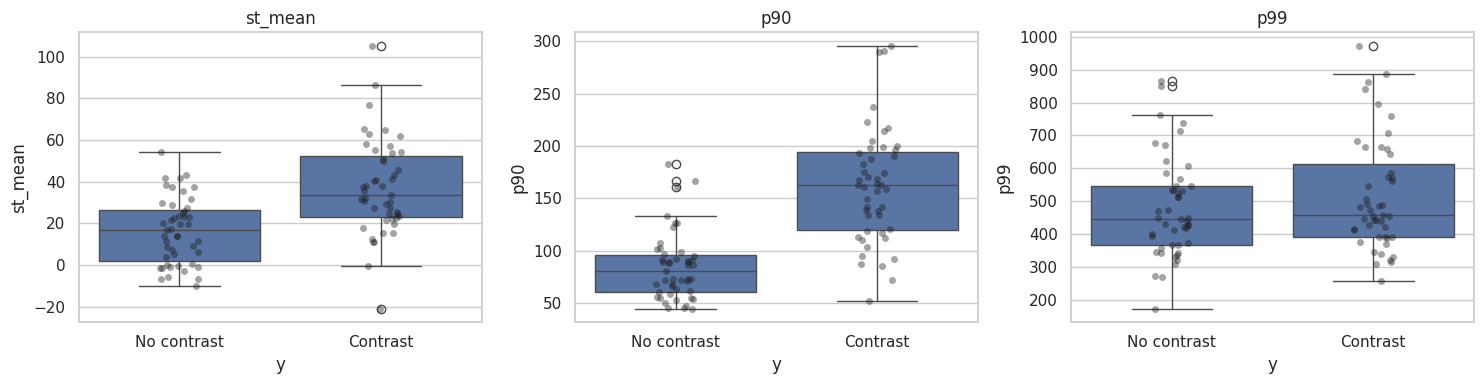

In [11]:
def body_mask(hu):
    m = hu > -300
    m = ndimage.binary_opening(m, iterations=2)
    lab, n = ndimage.label(m)
    if n == 0: return m
    sizes = ndimage.sum(m, lab, range(1, n + 1))
    return ndimage.binary_fill_holes(lab == (1 + np.argmax(sizes)))

rows = []
for h in hus:
    bm = body_mask(h); st = h[bm & (h > -100) & (h < 300)]   # soft-tissue pixels inside the body
    rows.append(dict(body_frac=bm.mean(), st_mean=st.mean() if st.size else np.nan, st_std=st.std() if st.size else np.nan,
                     p50=np.percentile(h[bm], 50), p90=np.percentile(h[bm], 90), p99=np.percentile(h[bm], 99)))
feat = pd.DataFrame(rows); feat['y'] = df['y'].values
print(feat.groupby('y').mean().round(2))
for c in ['st_mean', 'p90', 'p99']:
    print(f"{c}: Mann-Whitney p = {stats.mannwhitneyu(feat.loc[feat.y==0, c], feat.loc[feat.y==1, c]).pvalue:.4g}")
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for k, c in enumerate(['st_mean', 'p90', 'p99']):
    sns.boxplot(x='y', y=c, data=feat, ax=ax[k]); sns.stripplot(x='y', y=c, data=feat, color='k', alpha=.4, ax=ax[k])
    ax[k].set_xticklabels(['No contrast', 'Contrast']); ax[k].set_title(c)
plt.tight_layout(); plt.savefig(FIG_DIR / 'eda_hu_stats.png', dpi=150); plt.show()

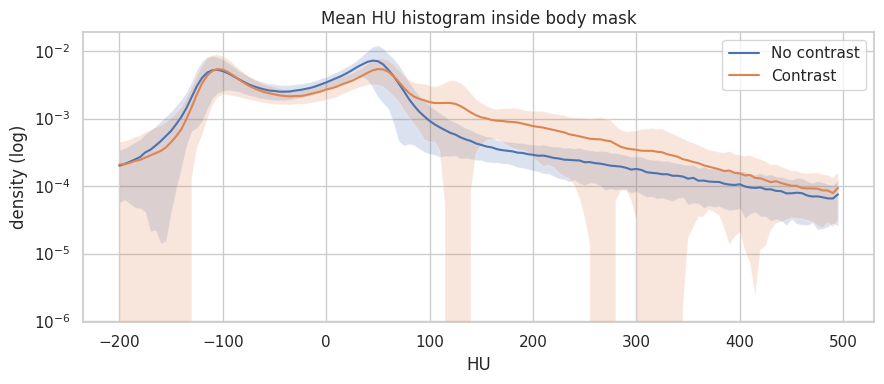

In [12]:
bins = np.linspace(-200, 500, 141); H = {0: [], 1: []}
for h, y in zip(hus, df.y):
    v = h[body_mask(h)]; H[y].append(np.histogram(v, bins=bins, density=True)[0])
plt.figure(figsize=(9, 4))
for y, lab in [(0, 'No contrast'), (1, 'Contrast')]:
    m = np.mean(H[y], 0); s = np.std(H[y], 0)
    plt.plot(bins[:-1], m, label=lab); plt.fill_between(bins[:-1], m - s, m + s, alpha=.2)
plt.yscale('log'); plt.xlabel('HU'); plt.ylabel('density (log)'); plt.legend(); plt.title('Mean HU histogram inside body mask')
plt.tight_layout(); plt.savefig(FIG_DIR / 'eda_hu_hist.png', dpi=150); plt.show()

### 2.4 Data quality: duplicates and outliers

In [13]:
hashes = [hashlib.md5(h.tobytes()).hexdigest() for h in hus]
print('Exact duplicate images:', len(hashes) - len(set(hashes)))
print('Images with NaN/Inf:', sum((~np.isfinite(h)).any() for h in hus))
print('Body fraction min/max: %.2f / %.2f' % (feat.body_frac.min(), feat.body_frac.max()))
# Possible shortcut: do body size or anatomy differ systematically by class?
print('Body-area fraction by class:'); print(feat.groupby('y')['body_frac'].describe().round(3))

Exact duplicate images: 0
Images with NaN/Inf: 0
Body fraction min/max: 0.18 / 0.83
Body-area fraction by class:
   count   mean    std    min    25%    50%    75%    max
y                                                        
0   47.0  0.462  0.179  0.181  0.294  0.474  0.595  0.785
1   47.0  0.531  0.121  0.279  0.439  0.554  0.599  0.831


## 3. Preprocessing and patient-aware splitting
- Convert to HU (done), apply a **soft-tissue window**, resize to 224x224, replicate to 3 channels for ImageNet backbones, normalise.
- With ~100 images, a single fixed split gives a noisy estimate, so we use **stratified, patient-grouped 5-fold cross-validation** and report mean and spread. Every image is predicted exactly once out-of-fold.
- **No intensity augmentation** in the main run: contrast is an intensity effect, so brightness or contrast jitter could remove the signal. Only flips and small geometric transforms are used.

In [14]:
IMG = 224
def prep(hu):
    x = torch.from_numpy(window(hu)).float()[None, None]
    x = F.interpolate(x, size=(IMG, IMG), mode='bilinear', antialias=True, align_corners=False)
    return x[0]
X = torch.stack([prep(h) for h in hus])            # (N, 1, 224, 224) in [0, 1]
y = df['y'].values.astype(np.float32)
groups = df['dcm_PatientID'].values
print(X.shape, y.mean())
skf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
folds = list(skf.split(np.zeros(len(y)), y, groups))
for k, (tr, te) in enumerate(folds):
    assert not set(groups[tr]) & set(groups[te]), 'patient leakage between train and test'
    print(f'fold {k}: train {len(tr)} (pos {int(y[tr].sum())}) | test {len(te)} (pos {int(y[te].sum())})')

torch.Size([94, 1, 224, 224]) 0.5
fold 0: train 70 (pos 36) | test 24 (pos 11)
fold 1: train 70 (pos 32) | test 24 (pos 15)
fold 2: train 81 (pos 42) | test 13 (pos 5)
fold 3: train 77 (pos 41) | test 17 (pos 6)
fold 4: train 78 (pos 37) | test 16 (pos 10)


## 4. Models

### 4.1 Baseline A: handcrafted HU features + logistic regression (and an age-only control)

In [15]:
def hu_features(h):
    v = h[body_mask(h)]
    hist = np.histogram(v, bins=np.linspace(-200, 400, 41), density=True)[0]
    return np.r_[hist, np.percentile(v, [5, 25, 50, 75, 90, 95, 99]), v.mean(), v.std()]
F_hu = np.stack([hu_features(h) for h in hus])

def cv_sklearn(Xf, name, C=1.0):
    oof = np.zeros(len(y)); fm = []
    for tr, te in folds:
        clf = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=2000)).fit(Xf[tr], y[tr])
        oof[te] = clf.predict_proba(Xf[te])[:, 1]
        fm.append(metrics(y[te], oof[te]))
    return oof, fm

def metrics(yt, pr, thr=0.5):
    yp = (pr >= thr).astype(int)
    auc = roc_auc_score(yt, pr) if len(set(yt)) > 1 else np.nan
    return dict(acc=accuracy_score(yt, yp), prec=precision_score(yt, yp, zero_division=0),
                rec=recall_score(yt, yp, zero_division=0), f1=f1_score(yt, yp, zero_division=0), auc=auc)

results = {}
results['HU features + LR'] = cv_sklearn(F_hu, 'hu', C=0.1)
if age_col:
    results['Age only (control)'] = cv_sklearn(df[[age_col]].values.astype(float), 'age')
for k, (oof, fm) in results.items(): print(k, pd.DataFrame(fm).mean().round(3).to_dict())

HU features + LR {'acc': 0.871, 'prec': 0.896, 'rec': 0.833, 'f1': 0.857, 'auc': 0.959}
Age only (control) {'acc': 0.583, 'prec': 0.633, 'rec': 0.555, 'f1': 0.544, 'auc': 0.578}


A high score from the age-only control would indicate that age is confounded with the label, and would be a warning about the dataset.

### 4.2 Deep models: small CNN and fine-tuned ResNet18

In [16]:
MEAN = torch.tensor([0.485, 0.456, 0.406])[:, None, None]; STD = torch.tensor([0.229, 0.224, 0.225])[:, None, None]
AUG = v2.Compose([v2.RandomHorizontalFlip(), v2.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.95, 1.05))])

class DS(Dataset):
    def __init__(s, idx, train): s.idx, s.train = idx, train
    def __len__(s): return len(s.idx)
    def __getitem__(s, i):
        j = s.idx[i]; x = X[j]
        if s.train: x = AUG(x)
        x = (x.repeat(3, 1, 1) - MEAN) / STD
        return x, torch.tensor(y[j])

class SmallCNN(nn.Module):
    def __init__(s):
        super().__init__()
        def blk(i, o): return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2))
        s.f = nn.Sequential(blk(3, 16), blk(16, 32), blk(32, 64), blk(64, 128))
        s.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(128, 1))
    def forward(s, x): return s.head(s.f(x)).squeeze(1)

def make_resnet18():
    m = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    m.fc = nn.Linear(m.fc.in_features, 1)
    class Wrap(nn.Module):
        def __init__(s, m): super().__init__(); s.m = m
        def forward(s, x): return s.m(x).squeeze(1)
    return Wrap(m)

@torch.no_grad()
def predict(model, idx):
    model.eval(); out = []
    for xb, _ in DataLoader(DS(idx, False), batch_size=32):
        out.append(torch.sigmoid(model(xb.to(device))).cpu())
    return torch.cat(out).numpy()

def run_cv(model_fn, epochs, lr, name, bs=16):
    oof = np.zeros(len(y)); fm = []; fold_models = []
    for k, (tr, te) in enumerate(folds):
        set_seed(SEED + k)
        model = model_fn().to(device)
        opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
        dl = DataLoader(DS(tr, True), batch_size=bs, shuffle=True, drop_last=len(tr) % bs == 1)
        for ep in range(epochs):                      # fixed epochs: the test fold is never used to pick a checkpoint
            model.train()
            for xb, yb in dl:
                xb, yb = xb.to(device), yb.to(device)
                opt.zero_grad(); loss = F.binary_cross_entropy_with_logits(model(xb), yb); loss.backward(); opt.step()
            sched.step()
        oof[te] = predict(model, te); fm.append(metrics(y[te], oof[te]))
        fold_models.append(model.cpu())
        print(f'{name} fold {k}: ' + ' '.join(f'{a}={b:.3f}' for a, b in fm[-1].items()))
    return oof, fm, fold_models

oof, fm, cnn_models = run_cv(SmallCNN, epochs=30, lr=1e-3, name='SmallCNN'); results['Small CNN'] = (oof, fm)
oof, fm, rn_models = run_cv(make_resnet18, epochs=15, lr=1e-4, name='ResNet18'); results['ResNet18 (fine-tuned)'] = (oof, fm)

SmallCNN fold 0: acc=0.792 prec=0.688 rec=1.000 f1=0.815 auc=0.909
SmallCNN fold 1: acc=0.667 prec=1.000 rec=0.467 f1=0.636 auc=0.956
SmallCNN fold 2: acc=0.846 prec=0.800 rec=0.800 f1=0.800 auc=0.875
SmallCNN fold 3: acc=0.941 prec=1.000 rec=0.833 f1=0.909 auc=0.985
SmallCNN fold 4: acc=0.812 prec=1.000 rec=0.700 f1=0.824 auc=0.950
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 192MB/s]


ResNet18 fold 0: acc=0.750 prec=0.667 rec=0.909 f1=0.769 auc=0.951
ResNet18 fold 1: acc=0.958 prec=1.000 rec=0.933 f1=0.966 auc=0.970
ResNet18 fold 2: acc=0.846 prec=1.000 rec=0.600 f1=0.750 auc=1.000
ResNet18 fold 3: acc=0.765 prec=0.600 rec=1.000 f1=0.750 auc=1.000
ResNet18 fold 4: acc=0.938 prec=1.000 rec=0.900 f1=0.947 auc=1.000


## 5. Results

In [17]:
def group_bootstrap_auc(yt, pr, grp, n=2000, seed=SEED):
    r = np.random.RandomState(seed); ug = np.unique(grp); out = []
    for _ in range(n):
        g = r.choice(ug, len(ug), replace=True)
        ii = np.concatenate([np.where(grp == k)[0] for k in g])
        if len(set(yt[ii])) > 1: out.append(roc_auc_score(yt[ii], pr[ii]))
    return np.percentile(out, [2.5, 97.5])

rows = []
for name, (oof, fm) in results.items():
    d = pd.DataFrame(fm); lo, hi = group_bootstrap_auc(y, oof, groups)
    rows.append({'Model': name, **{m.upper(): f'{d[m].mean():.3f} +/- {d[m].std():.3f}' for m in ['acc', 'prec', 'rec', 'f1', 'auc']},
                 'OOF AUC (95% CI)': f'{roc_auc_score(y, oof):.3f} [{lo:.3f}, {hi:.3f}]'})
res_table = pd.DataFrame(rows); res_table.to_csv(FIG_DIR / 'results_table.csv', index=False); res_table

,Model,ACC,PREC,REC,F1,AUC,OOF AUC (95% CI)
0,HU features + LR,0.871 +/- 0.033,0.896 +/- 0.097,0.833 +/- 0.100,0.857 +/- 0.046,0.959 +/- 0.029,"0.952 [0.905, 0.985]"
1,Age only (control),0.583 +/- 0.100,0.633 +/- 0.188,0.555 +/- 0.233,0.544 +/- 0.118,0.578 +/- 0.140,"0.543 [0.398, 0.683]"
2,Small CNN,0.812 +/- 0.099,0.897 +/- 0.146,0.760 +/- 0.196,0.797 +/- 0.099,0.935 +/- 0.043,"0.902 [0.838, 0.959]"
3,ResNet18 (fine-tuned),0.851 +/- 0.096,0.853 +/- 0.202,0.868 +/- 0.155,0.836 +/- 0.110,0.984 +/- 0.023,"0.948 [0.899, 0.985]"


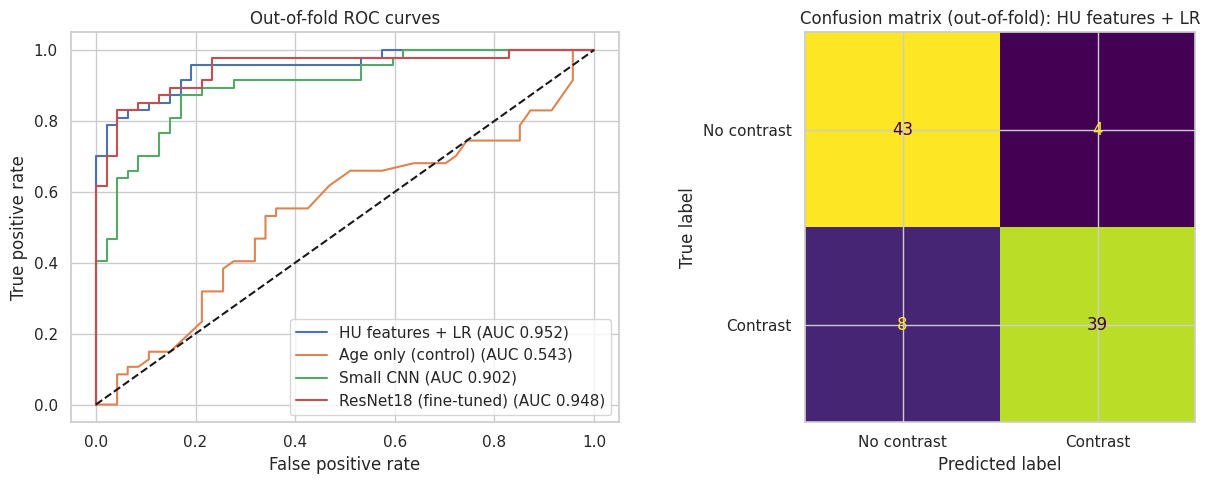

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for name, (oof, _) in results.items():
    fpr, tpr, _ = roc_curve(y, oof); ax[0].plot(fpr, tpr, label=f'{name} (AUC {roc_auc_score(y, oof):.3f})')
ax[0].plot([0, 1], [0, 1], 'k--'); ax[0].set_xlabel('False positive rate'); ax[0].set_ylabel('True positive rate')
ax[0].set_title('Out-of-fold ROC curves'); ax[0].legend(loc='lower right')
best = max(results, key=lambda k: roc_auc_score(y, results[k][0]))
cm = confusion_matrix(y, (results[best][0] >= 0.5).astype(int))
ConfusionMatrixDisplay(cm, display_labels=['No contrast', 'Contrast']).plot(ax=ax[1], colorbar=False)
ax[1].set_title(f'Confusion matrix (out-of-fold): {best}')
plt.tight_layout(); plt.savefig(FIG_DIR / 'results_roc_cm.png', dpi=150); plt.show()

## 6. Explainability: Grad-CAM (ResNet18)

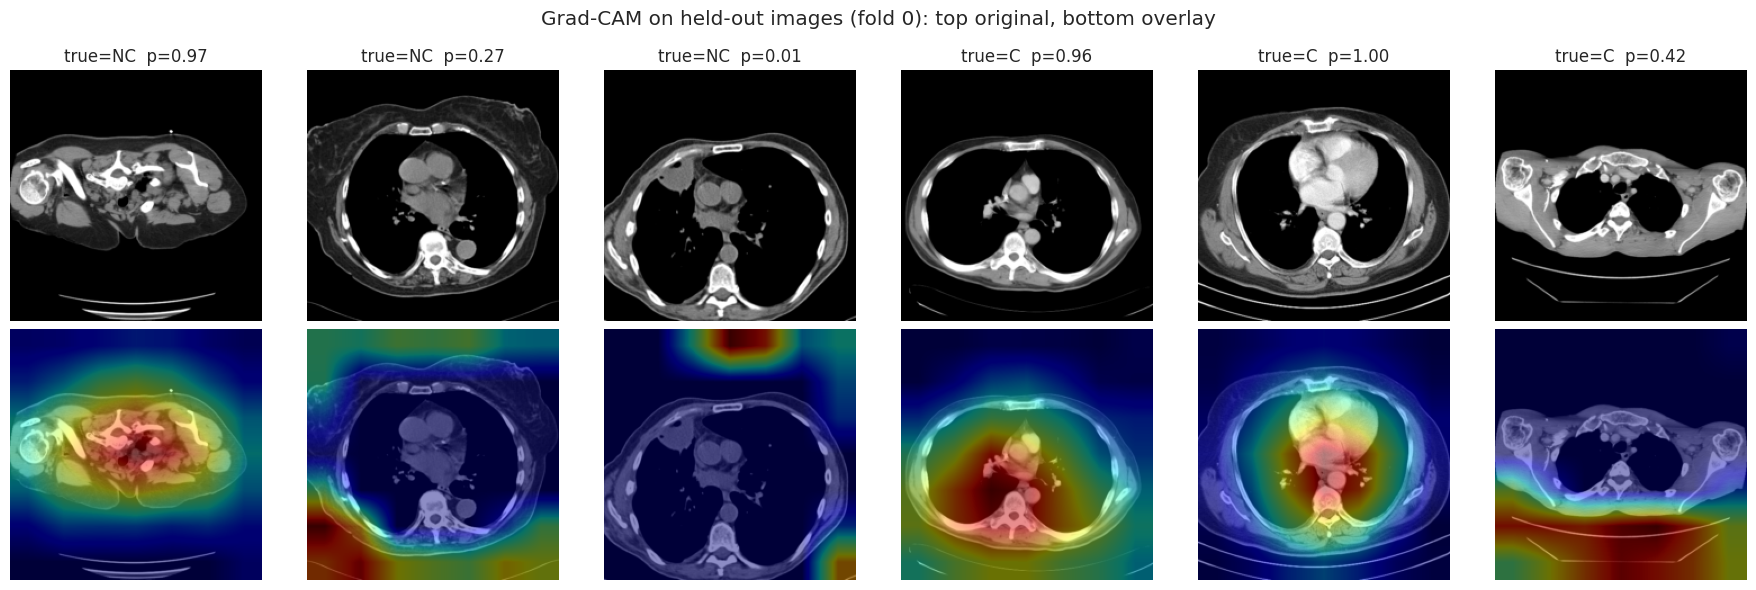

In [19]:
def gradcam(wrapped, x):
    wrapped = wrapped.to(device).eval(); layer = wrapped.m.layer4
    # Clear any stale hooks from previous failed executions
    layer._forward_hooks.clear()

    acts, grads = [], []

    def forward_hook(module, input, output):
        # Safely extract tensor from tuple/list if wrapped
        out_tensor = output[0] if isinstance(output, (tuple, list)) else output
        acts.append(out_tensor)

        # Register hook to capture gradients during backward pass
        h_grad = out_tensor.register_hook(lambda g: grads.append(g))
        return output

    h = layer.register_forward_hook(forward_hook)

    # Forward and backward pass
    out = wrapped(x.to(device)); wrapped.zero_grad(); out.sum().backward(); h.remove()

    w = grads[0].mean((2, 3), keepdim=True)
    cam = F.relu((w * acts[0]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=(IMG, IMG), mode='bilinear', align_corners=False)[:, 0]
    cam = (cam - cam.amin((1, 2), keepdim=True)) / (cam.amax((1, 2), keepdim=True) - cam.amin((1, 2), keepdim=True) + 1e-8)
    return cam.detach().cpu().numpy()

k = 0; tr, te = folds[k]; model_k = rn_models[k]
# Clean the model's hooks directly to be absolutely sure
if hasattr(model_k, 'm') and hasattr(model_k.m, 'layer4'):
    model_k.m.layer4._forward_hooks.clear()
    model_k.m.layer4._backward_hooks.clear()

sel = list(te[y[te] == 0][:3]) + list(te[y[te] == 1][:3])
xs = torch.stack([DS([i], False)[0][0] for i in sel]); cams = gradcam(model_k, xs); probs = predict(model_k.to(device), sel)
fig, axs = plt.subplots(2, len(sel), figsize=(3 * len(sel), 6))
for c, i in enumerate(sel):
    axs[0, c].imshow(X[i, 0], cmap='gray'); axs[0, c].set_title(f"true={'C' if y[i] else 'NC'}  p={probs[c]:.2f}"); axs[0, c].axis('off')
    axs[1, c].imshow(X[i, 0], cmap='gray'); axs[1, c].imshow(cams[c], cmap='jet', alpha=.45); axs[1, c].axis('off')
plt.suptitle('Grad-CAM on held-out images (fold 0): top original, bottom overlay'); plt.tight_layout()
plt.savefig(FIG_DIR / 'gradcam.png', dpi=150); plt.show()

Check whether the highlighted regions are plausible (vessels, enhancing organs, soft tissue) or look like shortcuts (image borders, table, scanner artefacts).

## 7. Limitations and notes for the report
- **Small sample:** about 100 slices. Report the out-of-fold AUC with its bootstrap confidence interval, and avoid strong claims.
- **Independence:** if each image has a unique PatientID, grouping cannot show whether images share patients or anatomy. Review the metadata checks in Section 2.1.
- **Shortcuts:** differences in body region, scanner or age between the classes can let a model succeed without detecting contrast. The age-only control, the body-area check and Grad-CAM are there to catch this.
- **Fixed epochs:** hyperparameters were not tuned on test folds. Any tuning should use a nested or separate validation split.
- **Scope:** results are a proof of concept without external validation, not evidence of clinical readiness.
- **Outputs:** figures and the results table are saved in `/content/results` for the Word report.